## Model comparison (next-day prediction)
Compares the tuned models from `03_logistic_regression`, `04_random_forest` and `05_gradient_boosting`.
Nothing is tuned here: each model is rebuilt from the settings and thresholds saved in `results/`, with the same data prep, splits and metrics.

**Main comparison:** 5-fold time-series CV PR-AUC on train + validation. The test year (2004, 11 ozone days) is shown too, but it is too small to rank models on its own.

In [1]:
import sys, json; sys.path.append("..")
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve, average_precision_score

from src.prep_data import get_splits, make_model_pipeline
from src.evaluate_model import evaluate, full_report, time_series_cv

RESULTS = Path("../results")

### 1. Load data and saved settings
The model builders below match the `make_model` functions in notebooks 03–05 exactly; only the hyperparameters come from the saved JSON files.

In [2]:
data = get_splits()
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]
features = data["features"]
X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val])

saved = {name: json.load(open(RESULTS / f"{file}_best.json")) for name, file in
         [("Logistic Regression", "logistic_regression"), ("Random Forest", "random_forest"),
          ("Gradient Boosting", "gradient_boosting")]}

def make_logreg(C=1.0):
    return make_model_pipeline(LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=42))

def make_rf(max_depth=None, min_samples_leaf=1, max_features="sqrt"):
    return make_model_pipeline(RandomForestClassifier(
        n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_features=max_features,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42), scale=False)

def make_gb(learning_rate=0.1, max_iter=100, max_depth=3, min_samples_leaf=20, l2_regularization=0.0):
    return make_model_pipeline(HistGradientBoostingClassifier(
        learning_rate=learning_rate, max_iter=max_iter, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
        l2_regularization=l2_regularization, class_weight="balanced", early_stopping=False, random_state=42), scale=False)

builders = {"Logistic Regression": make_logreg, "Random Forest": make_rf, "Gradient Boosting": make_gb}
make = {name: (lambda b=builders[name], p=saved[name]["params"]: b(**p)) for name in builders}
pd.DataFrame({n: {"params": s["params"], "thr_f1": round(s["thr_f1"], 3), "thr_r70": round(s["thr_r70"], 3)}
              for n, s in saved.items()}).T

Next-day target: dropped 9 rows with no following calendar day
Dropped 172 rows (6.8%) with >50% features missing (6 were positive); 2353 rows and 72 features remain
Remaining cells missing (to be imputed): 3.2%
train  1647 rows  1998-01-01 -> 2003-01-22  positives: 125  rate: 0.076
val     353 rows  2003-01-23 -> 2004-01-12  positives:  18  rate: 0.051
test    353 rows  2004-01-13 -> 2004-12-30  positives:  11  rate: 0.031


,params,thr_f1,thr_r70
Logistic Regression,{'C': 0.01},0.822,0.55
Random Forest,"{'max_depth': 8, 'max_features': 'sqrt', 'min_...",0.732,0.397
Gradient Boosting,"{'l2_regularization': 1, 'learning_rate': 0.01...",0.798,0.527


### 2. Time-series CV (main comparison)
Same 5 expanding-window folds for every model. These numbers should match the CV sections of notebooks 03–05.

In [3]:
cv = {name: time_series_cv(make[name](), X_dev, y_dev, n_splits=5) for name in make}

cv_summary = pd.DataFrame({name: {"cv_roc_auc": r.roc_auc.mean(), "cv_roc_auc_std": r.roc_auc.std(),
                                  "cv_pr_auc": r.pr_auc.mean(), "cv_pr_auc_std": r.pr_auc.std()}
                           for name, r in cv.items()}).T.sort_values("cv_pr_auc", ascending=False)
print(f"Random-guess PR-AUC on dev data: {y_dev.mean():.3f}")
cv_summary.round(3)

Random-guess PR-AUC on dev data: 0.071


,cv_roc_auc,cv_roc_auc_std,cv_pr_auc,cv_pr_auc_std
Logistic Regression,0.865,0.034,0.386,0.087
Random Forest,0.860,0.035,0.366,0.070
Gradient Boosting,0.841,0.031,0.337,0.091


#### PR-AUC per fold
The gaps between models are smaller than the spread across folds, so check how consistently each model wins fold by fold rather than relying on the means alone.

,Logistic Regression,Random Forest,Gradient Boosting,positives,best
fold,,,,,
1,0.392,0.470,0.458,29,Random Forest
2,0.494,0.395,0.400,39,Logistic Regression
3,0.249,0.288,0.293,16,Gradient Boosting
4,0.399,0.346,0.227,9,Logistic Regression
5,0.394,0.329,0.308,18,Logistic Regression


Folds won: {'Logistic Regression': 3, 'Random Forest': 1, 'Gradient Boosting': 1}


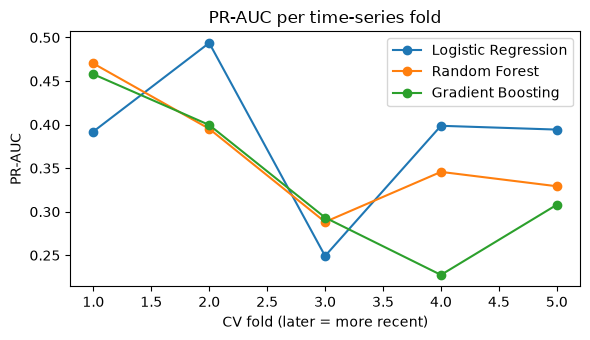

In [4]:
folds = pd.DataFrame({name: r.pr_auc.values for name, r in cv.items()}, index=cv["Random Forest"].fold)
folds["positives"] = cv["Random Forest"].positives.values
folds["best"] = folds[list(cv)].idxmax(axis=1)
display(folds.round(3))
print("Folds won:", folds["best"].value_counts().to_dict())

ax = folds[list(cv)].plot(marker="o", figsize=(6, 3.5))
ax.set_xlabel("CV fold (later = more recent)"); ax.set_ylabel("PR-AUC"); ax.set_title("PR-AUC per time-series fold")
plt.tight_layout(); plt.show()

### 3. Test set (2004) at the saved validation thresholds
Each model is fit on train only (same as in its own notebook), and both threshold rules come from validation.
With 11 ozone days, one more or one fewer caught day moves recall by 0.09, so treat these as noisy.

In [5]:
models, p_test, rows = {}, {}, []
for name in make:
    models[name] = make[name]().fit(X_train, y_train)
    p_test[name] = models[name].predict_proba(X_test)[:, 1]
    for rule in ["thr_f1", "thr_r70"]:
        thr = saved[name][rule]
        r = evaluate(f"{name} @{rule}", y_test, p_test[name], thr, verbose=False)
        pred = p_test[name] >= thr
        rows.append({"model": name, "threshold rule": "best-F1" if rule == "thr_f1" else "recall-70%",
                     "threshold": thr, "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"],
                     "precision": r["precision"], "recall": r["recall"], "f1": r["f1"],
                     "caught": int((pred & (y_test == 1)).sum()), "false_alarms": int((pred & (y_test == 0)).sum())})
test_table = pd.DataFrame(rows).set_index(["model", "threshold rule"])
print(f"Test: {int(y_test.sum())} ozone days out of {len(y_test)}; random-guess PR-AUC {y_test.mean():.3f}")
test_table.round(3)

Test: 11 ozone days out of 353; random-guess PR-AUC 0.031


threshold  roc_auc  pr_auc  precision  \
model               threshold rule                                          
Logistic Regression best-F1             0.822    0.962   0.547      0.308   
                    recall-70%          0.550    0.962   0.547      0.121   
Random Forest       best-F1             0.732    0.968   0.625      0.538   
                    recall-70%          0.397    0.968   0.625      0.124   
Gradient Boosting   best-F1             0.798    0.968   0.682      0.474   
                    recall-70%          0.527    0.968   0.682      0.110   

                                    recall     f1  caught  false_alarms  
model               threshold rule                                       
Logistic Regression best-F1          0.727  0.432       8            18  
                    recall-70%       1.000  0.216      11            80  
Random Forest       best-F1          0.636  0.583       7             6  
                    recall-70%       1.000  0.220      11            78  
Gradient Boosting   best-F1          0.818  0.600       9            10  
                    recall-70%       1.000  0.198      11            89

### 4. Precision-recall curves on test

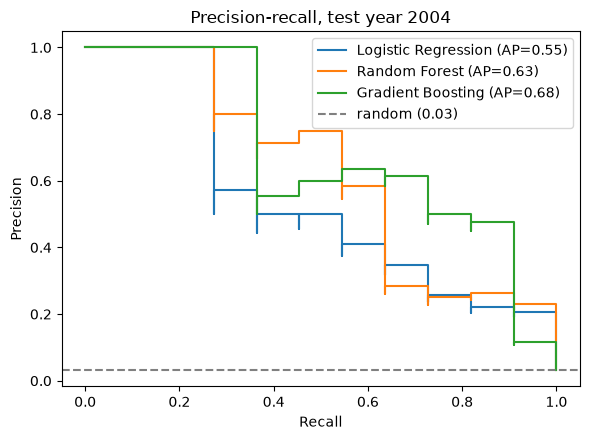

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name in make:
    prec, rec, _ = precision_recall_curve(y_test, p_test[name])
    ax.step(rec, prec, where="post", label=f"{name} (AP={average_precision_score(y_test, p_test[name]):.2f})")
ax.axhline(y_test.mean(), color="grey", ls="--", label=f"random ({y_test.mean():.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall, test year 2004"); ax.legend()
plt.tight_layout(); plt.show()

### 5. Which features matter? (permutation importance on validation)
Same method for all three models (drop in validation PR-AUC when a feature is shuffled), so the rankings are comparable.
Hourly features are strongly correlated, so read groups (e.g. afternoon temperatures) rather than single columns.

In [7]:
imp = {}
for name, m in models.items():
    perm = permutation_importance(m, X_val, y_val, scoring="average_precision", n_repeats=10, random_state=42, n_jobs=-1)
    imp[name] = pd.Series(perm.importances_mean, index=features)
top = pd.DataFrame({name: s.sort_values(ascending=False).head(10).index for name, s in imp.items()}, index=range(1, 11))
top

,Logistic Regression,Random Forest,Gradient Boosting
1,WSR20,V85,V85
2,V85,T17,T17
3,RH50,T18,T18
4,T50,WSR20,RH85
5,WSR19,T50,T15
6,SLP_,WSR4,T16
7,T17,T2,WSR23
8,T18,T0,WSR11
9,WSR23,T3,WSR20
10,WSR11,T19,WSR21


## Summary

**Setup:** All three models use the same next-day target, cleaning, chronological 70/15/15 split, median imputation inside the pipeline, and class weighting.
Each was tuned in its own notebook with the same 5-fold time-series CV (PR-AUC) on train + validation; the CV numbers here match those notebooks.

**Cross-validation (main comparison):**
| Model | CV ROC-AUC | CV PR-AUC | Folds won (PR-AUC) |
|---|---|---|---|
| Logistic Regression (`C=0.01`) | 0.865 ± 0.034 | **0.386 ± 0.087** | 3 of 5 (incl. the 3 most recent) |
| Random Forest | 0.860 ± 0.035 | 0.366 ± 0.070 | 1 of 5 |
| Gradient Boosting | 0.841 ± 0.031 | 0.337 ± 0.091 | 1 of 5 |

Random guessing gives PR-AUC ≈ 0.07, so all three models are about 5× better than chance. The differences between them (≤ 0.05) are smaller than the fold-to-fold spread (std ≈ 0.07–0.10), so **no model is clearly better**.
Regularized logistic regression is at least as good as the tree ensembles: the nonlinear models don't add much on this data, likely because there are only ~140 positive days to learn interactions from.

**Test year 2004 (11 ozone days), best-F1 thresholds from validation:**
| Model | PR-AUC | Precision | Recall | Caught | False alarms |
|---|---|---|---|---|---|
| Logistic Regression | 0.547 | 0.31 | 0.73 | 8 | 18 |
| Random Forest | 0.625 | 0.54 | 0.64 | 7 | 6 |
| Gradient Boosting | 0.682 | 0.47 | 0.82 | 9 | 10 |

Gradient Boosting has the best test PR-AUC and Random Forest the fewest false alarms, while logistic regression is last on test: the reverse of the CV ranking. With 11 positives, one day changes recall by 0.09, so this does not overturn the CV result.
The recall-70% thresholds catch all 11 days on test but raise 78–89 false alarms (precision ~0.10–0.12), too many for a practical warning; the best-F1 thresholds are the more usable rule.

**Features:** V85 (north–south wind at 850 hPa) is in the top two for every model. Afternoon temperatures (T15–T18) and wind speeds (WSR) come next.
The tree models lean on temperature; logistic regression also uses humidity/temperature at 500 hPa (RH50, T50) and sea-level pressure.

**Recommendation:** Use tuned logistic regression as the main model: best CV PR-AUC, wins the most recent folds, and is the simplest to explain.
Random Forest is a close second on CV, and both tree models did better on the 2004 test year. Report all three, and note that the gaps are within noise.
